In [94]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from mord import LogisticAT  # Ordinal logistic regression
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import tensorflow_addons as tfa
from keras import backend as K
from keras import losses
from imblearn.over_sampling import SMOTE, SMOTENC
from tensorflow.keras.layers import Lambda
from sklearn.utils.class_weight import compute_class_weight

%config Completer.use_jedi = False

In [95]:
r = pd.read_csv("/home/mojtaba.kananisarche/Zh/UTA/Blendshapes/Summary/Blendshapes_Summary_nap_1800_100.csv", index_col=0)
print(r.shape)
r.head()

(29708, 282)


,slice_index,filename,start_frame,end_frame,_neutral_mean,browDownLeft_mean,browDownRight_mean,browInnerUp_mean,browOuterUpLeft_mean,browOuterUpRight_mean,...,blinks_median_duration,blinks_std_duration,blinks_min_duration,blinks_max_duration,naps_count,naps_mean_duration,naps_median_duration,naps_std_duration,naps_min_duration,naps_max_duration
0,0,2_21_10_30fps_blendshape.csv,0,1799,0.0,0.020961,0.011672,0.091767,0.175344,0.169944,...,5.0,2.604979,1,14,0,0.0,0.0,0.0,0,0
1,1,2_21_10_30fps_blendshape.csv,100,1899,0.0,0.023722,0.013317,0.084261,0.166261,0.161839,...,5.0,2.259955,1,14,0,0.0,0.0,0.0,0,0
2,2,2_21_10_30fps_blendshape.csv,200,1999,0.0,0.024122,0.013600,0.087417,0.166378,0.161378,...,5.0,2.309985,1,14,0,0.0,0.0,0.0,0,0
3,3,2_21_10_30fps_blendshape.csv,300,2099,0.0,0.024967,0.013989,0.085200,0.162722,0.157400,...,5.0,2.132263,1,14,0,0.0,0.0,0.0,0,0
4,4,2_21_10_30fps_blendshape.csv,400,2199,0.0,0.026233,0.014633,0.082817,0.159100,0.153994,...,5.0,2.070616,1,14,0,0.0,0.0,0.0,0,0


In [96]:
r['target'] = r['filename'].apply(lambda x:int(x.split('_')[2].replace('10','2').replace('0','0').replace('5','1')))
r['fold'] = r['filename'].apply(lambda x: int(x.split('_')[0]))
r['subject_id'] = r['filename'].apply(lambda x: int(x.split('_')[1]))
r['target'].value_counts()

2    10416
1     9782
0     9510
Name: target, dtype: int64

In [93]:
# r['target'] = r['filename'].apply(lambda x:int(x.split('_')[2].replace('10','1').replace('0','-1').replace('5','0')))
# r['target'].value_counts()

In [89]:
# r['filename'].apply(lambda x: x.split('_')[0]).value_counts()

In [121]:
# def loss(y_true, y_pred):
#     weights = K.cast(K.abs(K.argmax(y_true, axis=1) - K.argmax(y_pred, axis=1))/(K.int_shape(y_pred)[1] - 1), dtype='float32')
#     return (1.0 + weights) * losses.categorical_crossentropy(y_true, y_pred)

def ordinal_accuracy(y_true, y_pred):
    # Define thresholds for classification
    thresholds = [0.33, 0.66]  # For mapping sigmoid to 0, 1, 2
    y_pred_class = np.digitize(y_pred, thresholds)  # Map sigmoid output to class labels (0, 1, 2)
    return tf.keras.metrics.sparse_categorical_accuracy(y_true, y_pred_class)

def step(val, steps, outputs):
    for i in range(len(steps)-1):
        low = steps[i]
        high = steps[i+1]
        if val >= low and val <= high:
            return outputs[i]
        
def report(model, x, y, output_dict):
    y_pred = [step(v,[0,0.33,0.66,1],[0,1,2]) for v in model.predict(x, verbose=0)]
#     y_pred = [step(v,[-1.5,-0.5,0.5,1.5],[-1,0,1]) for v in model.predict(x, verbose=0)]
#     y_pred = [step(v,[-3,-1,1,3],[-2,0,2]) for v in model.predict(x, verbose=0)]
    if output_dict:
        cr = classification_report(list(y), y_pred, output_dict=True)
        cr['confusion_matrix'] = list(confusion_matrix(list(y), y_pred))
        return cr
    
    print(classification_report(list(y), y_pred))
    print(confusion_matrix(list(y), y_pred))

In [133]:
class Model:
    def __init__(self, units, dropout_ratio, kernel_regularizer_l2, kernel_regularizer_l1, batch_size, num_classes, learning_rate, weight_decay, beta_1, beta_2, epsilon, cv_on, epochs, patience):
        self.units = units
        self.dropout_ratio = dropout_ratio
        self.kernel_regularizer_l2 = kernel_regularizer_l2
        self.kernel_regularizer_l1 = kernel_regularizer_l1
        self.batch_size = batch_size
        self.num_classes = num_classes
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay
        self.beta_1 = beta_1
        self.beta_2 = beta_2
        self.epsilon = epsilon
        self.cv_on = cv_on #subject_id, fold
        self.epochs = epochs
        self.patience = patience
        self.models = []
        self.histories = []
        self.reports = []
        
        
    def build_model(self, input_shape):
        model = keras.Sequential()
        model.add(layers.Input(shape=(input_shape,)))  # Ensure input shape matches your data

        for u in self.units:
            model.add(layers.Dense(u, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(self.kernel_regularizer_l2)))
            model.add(layers.BatchNormalization())
            model.add(layers.Dropout(self.dropout_ratio))

        # Final output layer
        model.add(layers.Dense(1, activation='sigmoid'))
#         model.add(layers.Dense(1))
#         model.add(layers.Dense(1, activation=lambda x: 3 * tf.keras.activations.sigmoid(x) - 1.5))  
#         model.add(Lambda(lambda x: 6 * tf.keras.activations.sigmoid(x) - 3))
#         model.add(layers.Dense(num_classes, activation='softmax' if num_classes > 1 else 'sigmoid'))

        model.compile(
            optimizer = keras.optimizers.AdamW(
                learning_rate=self.learning_rate,  # Adjust based on your needs
                weight_decay=self.weight_decay,    # Helps prevent overfitting
                beta_1=self.beta_1,                # Default value, controls momentum
                beta_2=self.beta_2,                # Default value, controls adaptive learning
                epsilon=self.epsilon               # Small constant for numerical stability
            ),
            loss='mse',
            metrics=['mae']
        )

        return model
    
    
    
    def get_reports(self):
        records = []

        for item in self.reports:
            base_info = {'test': item['test'], 'val': item['val']}
            for report_type in ['train_report', 'val_report', 'test_report']:
                report = item.get(report_type, {})
                for category, metrics in report.items():
                    if category == 'confusion_matrix':
                        cm_flat = np.array(metrics).flatten()
                        for i, value in enumerate(cm_flat):
                            records.append({**base_info, 'report_type': report_type, 'category': f'conf_matrix_{i}', 'metric': value})
                    elif isinstance(metrics, dict):
                        for metric, value in metrics.items():
                            records.append({**base_info, 'report_type': report_type, 'category': category, 'metric_name': metric, 'metric_value': value})
                    else:
                        records.append({**base_info, 'report_type': report_type, 'category': 'macro avg', 'metric_name': category, 'metric_value': metrics})

        return pd.DataFrame(records)

        
    
    def test_model(self, data):
        unique = data[self.cv_on].unique()
        for i in unique:
            for j in unique:
                if i==j:
                    continue
                if i>2 or j>4:
                    continue
                    
                print("==============================")
                print(f"Test {i} & Validation {j}")
                
                train = data[~data[self.cv_on].isin([i,j])].reset_index(drop=True)
                val   = data[data[self.cv_on]==j].reset_index(drop=True)
                test  = data[data[self.cv_on]==i].reset_index(drop=True)
                
                X_train = train.drop(columns=['slice_index', 'filename', 'start_frame', 'end_frame', 'target', 'fold', 'subject_id'])
                X_val   = val.drop(columns=['slice_index', 'filename', 'start_frame', 'end_frame', 'target', 'fold', 'subject_id'])
                X_test  = test.drop(columns=['slice_index', 'filename', 'start_frame', 'end_frame', 'target', 'fold', 'subject_id'])
                
                y_train = train['target']
                y_val   = val['target']
                y_test  = test['target']
                
                scaler  = StandardScaler().fit(X_train)
                
                X_train = scaler.transform(X_train)
                X_val   = scaler.transform(X_val)
                X_test  = scaler.transform(X_test)
                
                print(f"train dataset dimension {X_train.shape}")
                print(f"validation dataset dimension {X_val.shape}")
                print(f"test dataset dimension {X_test.shape}")
                
                classes = [0, 1, 2]
                class_weights = compute_class_weight('balanced', classes=classes, y=y_train)
                class_weight_dict = {}
                for c, w in zip(classes, class_weights):
                    class_weight_dict[c] = w
                
                print(class_weight_dict)
                
                model = self.build_model(X_train.shape[1])
                
                # Train the model
                history = model.fit(
                    X_train, 
                    y_train,
                    validation_data=(X_val, y_val),
                    epochs=self.epochs,
                    batch_size=self.batch_size,
                    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=self.patience, restore_best_weights=True)],
                    verbose=0,
                    class_weight=class_weight_dict
                )
                
                self.models.append(model)
                self.histories.append(history)
                
                train_report = report(model, X_train, y_train, True)
                val_report   = report(model, X_val, y_val, True)
                test_report  = report(model, X_test, y_test, True)
                
                self.reports.append({'test' : i, 
                                     'val' : j, 
                                     'train_report' : train_report, 
                                     'val_report' : val_report, 
                                     'test_report' : test_report})

In [142]:
m2 = Model(units = [150,50,20], 
          dropout_ratio = 0.5, 
          kernel_regularizer_l2 = 0, 
          kernel_regularizer_l1 = 0, 
          batch_size = 8, 
          num_classes = 3, 
          learning_rate = 1e-3, 
          weight_decay = 1e-4, 
          beta_1 = 0.9, 
          beta_2 = 0.999, 
          epsilon = 1e-7, 
          cv_on = 'subject_id', 
          epochs = 200, 
          patience = 100)

m2.test_model(r)

Test 1 & Validation 4
train dataset dimension (28721, 278)
validation dataset dimension (499, 278)
test dataset dimension (488, 278)
{0: 1.042883079157589, 1: 1.0125506786532699, 2: 0.9492035164254081}
Test 1 & Validation 3
train dataset dimension (28695, 278)
validation dataset dimension (525, 278)
test dataset dimension (488, 278)
{0: 1.0445560773178988, 1: 1.0119551417689379, 2: 0.9483442395399564}
Test 1 & Validation 2
train dataset dimension (28727, 278)
validation dataset dimension (493, 278)
test dataset dimension (488, 278)
{0: 1.0428737384738256, 1: 1.0126551043429215, 2: 0.949119503089173}
Test 2 & Validation 4
train dataset dimension (28716, 278)
validation dataset dimension (499, 278)
test dataset dimension (493, 278)
{0: 1.0429287426454565, 1: 1.0125885962128425, 2: 0.9491323748140803}
Test 2 & Validation 1
train dataset dimension (28727, 278)
validation dataset dimension (488, 278)
test dataset dimension (493, 278)
{0: 1.0428737384738256, 1: 1.0126551043429215, 2: 0.94911

In [143]:
df2 = m.get_reports()
df2[(df2['metric_name'] == 'accuracy') & (df2['report_type'] == 'train_report')]

,test,val,report_type,category,metric_name,metric_value,metric
12,1,4,train_report,macro avg,accuracy,0.653668,NaN
102,1,3,train_report,macro avg,accuracy,0.660777,NaN
192,1,2,train_report,macro avg,accuracy,0.640652,NaN
282,2,4,train_report,macro avg,accuracy,0.652389,NaN
372,2,1,train_report,macro avg,accuracy,0.621401,NaN
462,2,3,train_report,macro avg,accuracy,0.659777,NaN


In [144]:
# df2 = m.get_reports()
df2[(df2['metric_name'] == 'accuracy') & (df2['report_type'] == 'test_report')]

,test,val,report_type,category,metric_name,metric_value,metric
72,1,4,test_report,macro avg,accuracy,0.495902,NaN
162,1,3,test_report,macro avg,accuracy,0.512295,NaN
252,1,2,test_report,macro avg,accuracy,0.489754,NaN
342,2,4,test_report,macro avg,accuracy,0.541582,NaN
432,2,1,test_report,macro avg,accuracy,0.537525,NaN
522,2,3,test_report,macro avg,accuracy,0.572008,NaN


In [148]:
# df2 = m.get_reports()
df2[(df2['metric_name'] == 'accuracy') & (df2['report_type'] == 'val_report')]

,test,val,report_type,category,metric_name,metric_value,metric
42,1,4,val_report,macro avg,accuracy,0.659319,NaN
132,1,3,val_report,macro avg,accuracy,0.447619,NaN
222,1,2,val_report,macro avg,accuracy,0.612576,NaN
312,2,4,val_report,macro avg,accuracy,0.651303,NaN
402,2,1,val_report,macro avg,accuracy,0.538934,NaN
492,2,3,val_report,macro avg,accuracy,0.382857,NaN


In [145]:
df2[(df2['metric_name'] == 'accuracy') & (df2['report_type'] == 'test_report')].mean()

test            1.500000
val             2.833333
metric_value    0.524844
metric               NaN
dtype: float64

In [123]:
m = Model(units = [150,50,20], 
          dropout_ratio = 0.5, 
          kernel_regularizer_l2 = 0, 
          kernel_regularizer_l1 = 0, 
          batch_size = 16, 
          num_classes = 3, 
          learning_rate = 1e-3, 
          weight_decay = 1e-4, 
          beta_1 = 0.9, 
          beta_2 = 0.999, 
          epsilon = 1e-7, 
          cv_on = 'subject_id', 
          epochs = 200, 
          patience = 50)

In [124]:
m.test_model(r)

Test 1 & Validation 4
train dataset dimension (28721, 278)
validation dataset dimension (499, 278)
test dataset dimension (488, 278)
{0: 1.042883079157589, 1: 1.0125506786532699, 2: 0.9492035164254081}


/home/mojtaba.kananisarche/.local/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/mojtaba.kananisarche/.local/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/mojtaba.kananisarche/.local/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result)

Test 1 & Validation 3
train dataset dimension (28695, 278)
validation dataset dimension (525, 278)
test dataset dimension (488, 278)
{0: 1.0445560773178988, 1: 1.0119551417689379, 2: 0.9483442395399564}


/home/mojtaba.kananisarche/.local/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/mojtaba.kananisarche/.local/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/mojtaba.kananisarche/.local/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result)

Test 1 & Validation 2
train dataset dimension (28727, 278)
validation dataset dimension (493, 278)
test dataset dimension (488, 278)
{0: 1.0428737384738256, 1: 1.0126551043429215, 2: 0.949119503089173}
Test 2 & Validation 4
train dataset dimension (28716, 278)
validation dataset dimension (499, 278)
test dataset dimension (493, 278)
{0: 1.0429287426454565, 1: 1.0125885962128425, 2: 0.9491323748140803}


/home/mojtaba.kananisarche/.local/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/mojtaba.kananisarche/.local/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/mojtaba.kananisarche/.local/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result)

Test 2 & Validation 1
train dataset dimension (28727, 278)
validation dataset dimension (488, 278)
test dataset dimension (493, 278)
{0: 1.0428737384738256, 1: 1.0126551043429215, 2: 0.949119503089173}
Test 2 & Validation 3
train dataset dimension (28690, 278)
validation dataset dimension (525, 278)
test dataset dimension (493, 278)
{0: 1.0446022210085564, 1: 1.0119929453262786, 2: 0.9482730127251694}


In [125]:
df = m.get_reports()
df[(df['metric_name'] == 'accuracy') & (df['report_type'] == 'train_report')]

,test,val,report_type,category,metric_name,metric_value,metric
12,1,4,train_report,macro avg,accuracy,0.653668,NaN
102,1,3,train_report,macro avg,accuracy,0.660777,NaN
192,1,2,train_report,macro avg,accuracy,0.640652,NaN
282,2,4,train_report,macro avg,accuracy,0.652389,NaN
372,2,1,train_report,macro avg,accuracy,0.621401,NaN
462,2,3,train_report,macro avg,accuracy,0.659777,NaN


In [127]:
df[(df['metric_name'] == 'accuracy') & (df['report_type'] == 'val_report')].mean()

test            1.500000
val             2.833333
metric_value    0.548768
metric               NaN
dtype: float64

In [132]:
df[(df['category'].isin(['conf_matrix_0',
       'conf_matrix_1', 'conf_matrix_2', 'conf_matrix_3', 'conf_matrix_4',
       'conf_matrix_5', 'conf_matrix_6', 'conf_matrix_7', 'conf_matrix_8'])) & 
   (df['report_type'] == 'test_report')].groupby("category").sum()

,test,val,metric_value,metric
category,,,,
conf_matrix_0,9,17,0.0,883.0
conf_matrix_1,9,17,0.0,6.0
conf_matrix_2,9,17,0.0,95.0
conf_matrix_3,9,17,0.0,348.0
conf_matrix_4,9,17,0.0,9.0
conf_matrix_5,9,17,0.0,621.0
conf_matrix_6,9,17,0.0,318.0
conf_matrix_7,9,17,0.0,10.0
conf_matrix_8,9,17,0.0,653.0


In [116]:
df

,test,val,report_type,category,metric_name,metric_value,metric
0,1,4,train_report,0,precision,0.981026,NaN
1,1,4,train_report,0,recall,0.968736,NaN
2,1,4,train_report,0,f1-score,0.974842,NaN
3,1,4,train_report,0,support,9180.000000,NaN
4,1,4,train_report,1,precision,0.474054,NaN
...,...,...,...,...,...,...,...
85,1,4,test_report,conf_matrix_4,NaN,NaN,70.0
86,1,4,test_report,conf_matrix_5,NaN,NaN,0.0
87,1,4,test_report,conf_matrix_6,NaN,NaN,80.0
88,1,4,test_report,conf_matrix_7,NaN,NaN,83.0


In [44]:
df[(df['metric_name'] == 'accuracy') & (df['report_type'] == 'val_report')].mean()

test            1.000000
val             3.000000
metric_value    0.491676
metric               NaN
dtype: float64

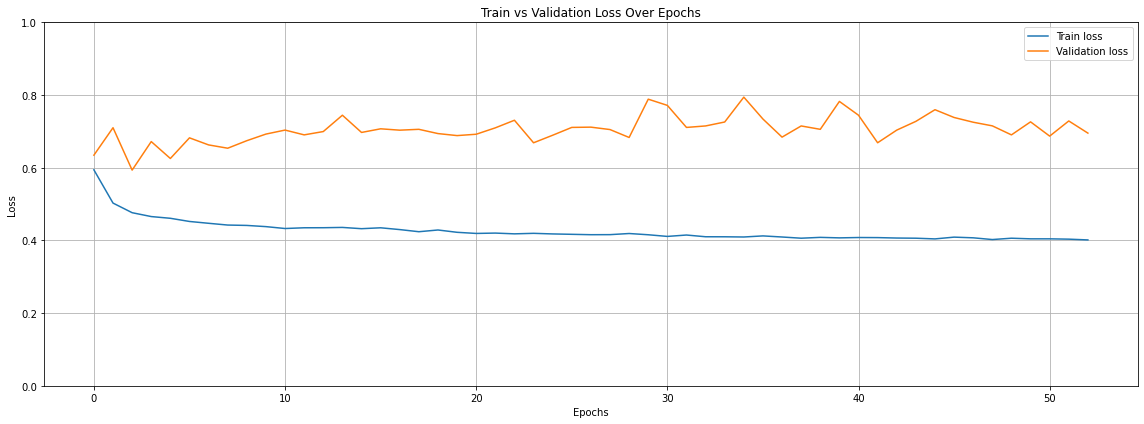

In [141]:
history = m.histories[4]
# Create a 1-row, 2-column layout
plt.figure(figsize=(16, 6))

# Plot for loss
# plt.subplot(1, 2, 1)  # (rows, columns, index)
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.ylim(0,1)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Train vs Validation Loss Over Epochs')
plt.legend()
plt.grid()

# # Plot for accuracy
# plt.subplot(1, 2, 2)  # (rows, columns, index)
# plt.plot(history.history['accuracy'], label='Train accuracy')
# plt.plot(history.history['val_accuracy'], label='Validation accuracy')
# plt.ylim(0,1)
# plt.xlabel('Epochs')
# plt.ylabel('accuracy')
# plt.title('Train vs Validation accuracy Over Epochs')
# plt.legend()
# plt.grid()

# Show the plots
plt.tight_layout()
plt.show()

In [118]:
df[(df['category'].isin(['conf_matrix_0',
       'conf_matrix_1', 'conf_matrix_2', 'conf_matrix_3', 'conf_matrix_4',
       'conf_matrix_5', 'conf_matrix_6', 'conf_matrix_7', 'conf_matrix_8'])) & 
   (df['report_type'] == 'test_report')]

,test,val,report_type,category,metric_name,metric_value,metric
81,1,4,test_report,conf_matrix_0,NaN,NaN,163.0
82,1,4,test_report,conf_matrix_1,NaN,NaN,0.0
83,1,4,test_report,conf_matrix_2,NaN,NaN,0.0
84,1,4,test_report,conf_matrix_3,NaN,NaN,92.0
85,1,4,test_report,conf_matrix_4,NaN,NaN,70.0
86,1,4,test_report,conf_matrix_5,NaN,NaN,0.0
87,1,4,test_report,conf_matrix_6,NaN,NaN,80.0
88,1,4,test_report,conf_matrix_7,NaN,NaN,83.0
89,1,4,test_report,conf_matrix_8,NaN,NaN,0.0


In [27]:
df['category'].unique()

array(['-1', '0', '1', 'macro avg', 'weighted avg', 'conf_matrix_0',
       'conf_matrix_1', 'conf_matrix_2', 'conf_matrix_3', 'conf_matrix_4',
       'conf_matrix_5', 'conf_matrix_6', 'conf_matrix_7', 'conf_matrix_8'],
      dtype=object)

In [59]:
# num_layers = 6
# num_units = 8
units = [10]
dropout_ratio = 0.5
batch_size = 512

# Define the neural network model
def build_model(input_shape, num_classes):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_shape,)))  # Ensure input shape matches your data

    for u in units:
        model.add(layers.Dense(u, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.)))
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(dropout_ratio))
    
    # Final output layer
    model.add(layers.Dense(1, activation=lambda x: 3 * tf.keras.activations.sigmoid(x) - 1.5))  

#     model.add(layers.Dense(num_classes, activation='softmax' if num_classes > 1 else 'sigmoid'))

    model.compile(
        optimizer = keras.optimizers.AdamW(
            learning_rate=5e-4,  # Adjust based on your needs
            weight_decay=1e-4,   # Helps prevent overfitting
            beta_1=0.9,          # Default value, controls momentum
            beta_2=0.999,        # Default value, controls adaptive learning
            epsilon=1e-7         # Small constant for numerical stability
        ),
        loss='mse',
        metrics=['accuracy']
    )
    
    return model

Test : 1   Validation : 2
train dataset dimension (17756, 278)
validation dataset dimension (6114, 278)
test dataset dimension (5838, 278)
Epoch 1/200
35/35 [==============================] - 2s 6ms/step - loss: 0.9592 - accuracy: 0.3839 - val_loss: 0.7974 - val_accuracy: 0.4213
Epoch 2/200
35/35 [==============================] - 0s 2ms/step - loss: 0.7583 - accuracy: 0.4110 - val_loss: 0.7966 - val_accuracy: 0.4325
Epoch 3/200
35/35 [==============================] - 0s 2ms/step - loss: 0.6556 - accuracy: 0.4329 - val_loss: 0.8001 - val_accuracy: 0.4326
Epoch 4/200
35/35 [==============================] - 0s 2ms/step - loss: 0.6014 - accuracy: 0.4462 - val_loss: 0.8080 - val_accuracy: 0.4244
Epoch 5/200
35/35 [==============================] - 0s 2ms/step - loss: 0.5489 - accuracy: 0.4532 - val_loss: 0.7960 - val_accuracy: 0.4174
Epoch 6/200
35/35 [==============================] - 0s 2ms/step - loss: 0.5124 - accuracy: 0.4632 - val_loss: 0.7741 - val_accuracy: 0.4169
Epoch 7/200
35/

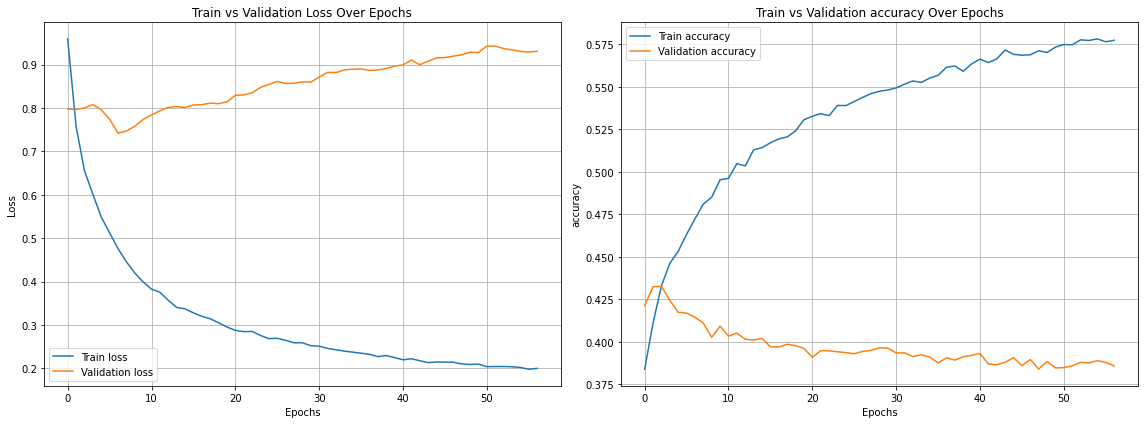

              precision    recall  f1-score   support

          -1       0.78      0.47      0.58      5540
           0       0.46      0.76      0.57      5792
           1       0.84      0.64      0.72      6424

    accuracy                           0.62     17756
   macro avg       0.69      0.62      0.63     17756
weighted avg       0.70      0.62      0.63     17756

[[2584 2922   34]
 [ 648 4405  739]
 [  79 2255 4090]]
              precision    recall  f1-score   support

          -1       0.73      0.44      0.55      7533
           0       0.44      0.72      0.55      7836
           1       0.77      0.59      0.67      8501

    accuracy                           0.59     23870
   macro avg       0.65      0.58      0.59     23870
weighted avg       0.65      0.59      0.59     23870

[[3288 3941  304]
 [ 970 5666 1200]
 [ 273 3187 5041]]
              precision    recall  f1-score   support

          -1       0.47      0.59      0.52      1977
           0       

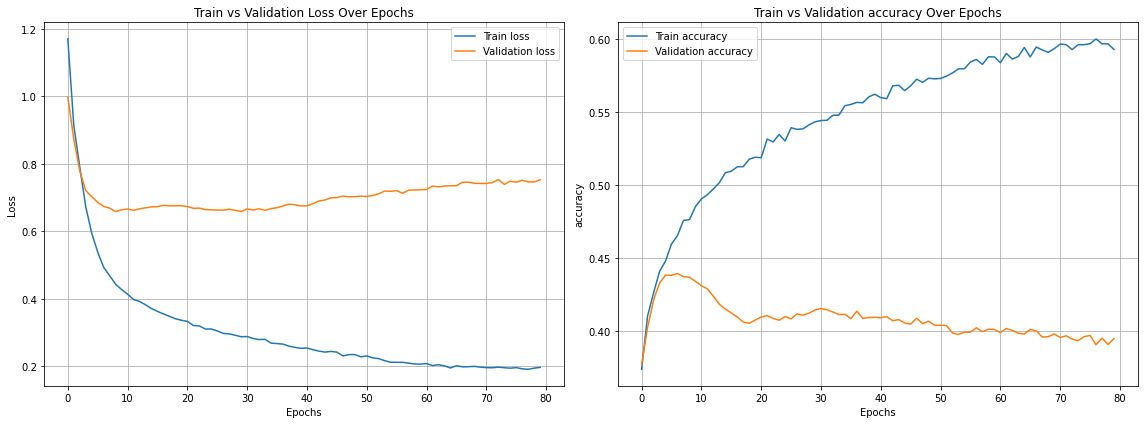

              precision    recall  f1-score   support

          -1       0.96      0.71      0.82      5353
           0       0.64      0.90      0.75      5663
           1       0.93      0.78      0.85      6476

    accuracy                           0.80     17492
   macro avg       0.84      0.80      0.80     17492
weighted avg       0.84      0.80      0.81     17492

[[3811 1515   27]
 [ 156 5123  384]
 [   5 1398 5073]]
              precision    recall  f1-score   support

          -1       0.87      0.59      0.70      7533
           0       0.56      0.82      0.67      7836
           1       0.83      0.72      0.77      8501

    accuracy                           0.71     23870
   macro avg       0.75      0.71      0.71     23870
weighted avg       0.76      0.71      0.72     23870

[[4466 2788  279]
 [ 480 6409  947]
 [ 197 2197 6107]]
              precision    recall  f1-score   support

          -1       0.49      0.50      0.49      1977
           0       

In [53]:



for i in range(1,2):
    for j in range(2,4):
        if j == i:
            continue
        print("========================================================================================================================================")
        print(f"Test : {i}   Validation : {j}")

        train = r[r['fold']!=i].reset_index(drop=True)
        test  = r[r['fold']==i].reset_index(drop=True)
        
        val_idx   = list(train[train['fold']==j].index)
        train_idx = list(train[train['fold']!=j].index)
        
        X_train = train.drop(columns=['slice_index', 'filename', 'start_frame', 'end_frame', 'target', 'fold', 'subject_id'])
        y_train = train['target']
#         y_train = keras.utils.to_categorical(train['target'], num_classes=3)

        X_test  = test.drop(columns=['slice_index', 'filename', 'start_frame', 'end_frame', 'target', 'fold', 'subject_id'])
        y_test  = test['target']
#         y_test  = keras.utils.to_categorical(test['target'], num_classes=3)

        scaler         = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled  = scaler.transform(X_test)
        
        X_val = X_train_scaled[val_idx]
        y_val = y_train[val_idx]
        
        X_train_final = X_train_scaled[train_idx]
        y_train_final = y_train[train_idx]
        
        print(f"train dataset dimension {X_train_final.shape}")
        print(f"validation dataset dimension {X_val.shape}")
        print(f"test dataset dimension {X_test_scaled.shape}")

        # Set input and output parameters
        input_shape = X_train.shape[1]  # Number of features
        num_classes = 3  # Determine if it's binary or multi-class classification

        # Build and summarize the model
        model = build_model(input_shape, num_classes)
#         print(model.summary())

        # Train the model
        history = model.fit(
            X_train_final, y_train_final,
            validation_data=(X_val, y_val),
            epochs=200,
            batch_size=batch_size,
            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)],
            verbose=1
        )

        # Create a 1-row, 2-column layout
        plt.figure(figsize=(16, 6))

        # Plot for loss
        plt.subplot(1, 2, 1)  # (rows, columns, index)
        plt.plot(history.history['loss'], label='Train loss')
        plt.plot(history.history['val_loss'], label='Validation loss')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.title('Train vs Validation Loss Over Epochs')
        plt.legend()
        plt.grid()

        # Plot for accuracy
        plt.subplot(1, 2, 2)  # (rows, columns, index)
        plt.plot(history.history['accuracy'], label='Train accuracy')
        plt.plot(history.history['val_accuracy'], label='Validation accuracy')
        plt.xlabel('Epochs')
        plt.ylabel('accuracy')
        plt.title('Train vs Validation accuracy Over Epochs')
        plt.legend()
        plt.grid()

        # Show the plots
        plt.tight_layout()
        plt.show()
        
        report(model, X_train_final, y_train_final)
        report(model, X_train_scaled, y_train)
        report(model, X_test_scaled, y_test)
        
        print("========================================================================================================================================\n\n\n")

In [82]:
report(model, X_train_final, y_train_final)

              precision    recall  f1-score   support

          -1       0.96      0.71      0.82      5353
           0       0.64      0.90      0.75      5663
           1       0.93      0.78      0.85      6476

    accuracy                           0.80     17492
   macro avg       0.84      0.80      0.80     17492
weighted avg       0.84      0.80      0.81     17492

[[3811 1515   27]
 [ 156 5123  384]
 [   5 1398 5073]]


In [81]:
history.test

In [70]:
print(classification_report(y.argmax(axis=1), list(model.predict(x).argmax(axis=1))))
#     print(confusion_matrix(y, list(model.predict(x).argmax(axis=1))))

13/13 [==============================] - 0s 775us/step
              precision    recall  f1-score   support

           0       0.47      0.55      0.51       131
           1       0.33      0.34      0.33       128
           2       0.50      0.40      0.45       127

    accuracy                           0.43       386
   macro avg       0.43      0.43      0.43       386
weighted avg       0.43      0.43      0.43       386



In [44]:
# X = r.drop(columns=['slice_index', 'filename', 'start_frame', 'end_frame', 'target', 'fold'])
# y = r['target']
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# y_train = keras.utils.to_categorical(y_train, num_classes=3)
# y_test = keras.utils.to_categorical(y_test, num_classes=3)
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

In [46]:
# # Set input and output parameters
# input_shape = 218  # Number of features
# num_classes = len(y_train[0])  # Determine if it's binary or multi-class classification

# # Build and summarize the model
# model = build_model(input_shape, num_classes)
# model.summary()

In [47]:
# # Train the model
# history = model.fit(
#     X_train_scaled, y_train,
#     validation_data=(X_test_scaled, y_test),
#     epochs=200,
#     batch_size=32,
#     callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)]
# )

In [49]:
# y_train_pred = model.predict(X_train_scaled)
# y_test_pred = model.predict(X_test_scaled)

In [50]:
# def report(x, y):
#     print(classification_report(y, list(model.predict(x).argmax(axis=1))))
#     print(confusion_matrix(y, list(model.predict(x).argmax(axis=1))))

In [51]:
# list(model.predict(X_train_scaled).argmax(axis=1))

In [115]:
report(X_train_scaled, y_train)

49/49 [==============================] - 0s 757us/step


ValueError: Classification metrics can't handle a mix of multilabel-indicator and multiclass targets

In [79]:
report(X_test_scaled, y_test)

13/13 [==============================] - 0s 762us/step
              precision    recall  f1-score   support

           0       0.87      0.88      0.87       124
           1       0.84      0.81      0.82       129
           2       0.84      0.86      0.85       137

    accuracy                           0.85       390
   macro avg       0.85      0.85      0.85       390
weighted avg       0.85      0.85      0.85       390

13/13 [==============================] - 0s 791us/step
[[109   9   6]
 [  9 104  16]
 [  8  11 118]]


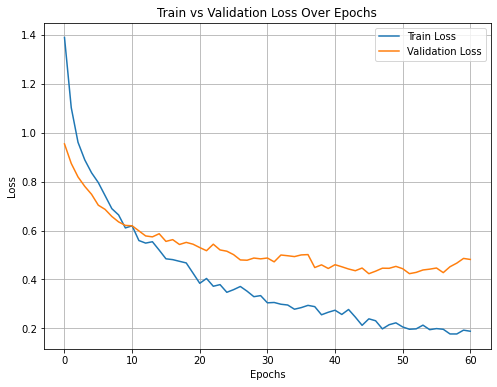

In [80]:
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Train vs Validation Loss Over Epochs')
plt.legend()
plt.grid()
plt.show()